## Dependencies

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from IPython.display import display
from pdf2image import convert_from_path

In [3]:
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import ios

## Setup

In [6]:
VERSION = 3
RANDOM_SEED = 1

VAR_X = ['mean', 'median', 'mode']
DIR = f'../../results/v{VERSION}/gender/predictions/comparison/rs{RANDOM_SEED}/regression/_<VAR_X>/*'
METRIC = 'test_rmse'

## Data

In [7]:
df_results_mean = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mean'))
df_results_median = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'median'))
df_results_mode = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mode'))
df_results = pd.concat([df_results_mean, df_results_median, df_results_mode], ignore_index=True)
df_results.shape

(10, 20)

In [8]:
cols = ['y','features_id','features','train_eval','test_r2','test_rmse']
df_results[cols].sort_values(METRIC, ascending=True)

,y,features_id,features,train_eval,test_r2,test_rmse
0,mean,6,[mean_ngender_rn],0.116041,0.746892,0.123599
9,mean,7,[mean_ngender_rw],0.121203,0.737953,0.125763
2,mean,0,[ngender_r],0.115745,0.700918,0.134356
7,mean,9,[mean_ngender_rnw],0.116172,0.649321,0.145485
1,mean,8,[mean_ngender_nw],0.132197,0.547510,0.165260
3,mean,1,[ngender_n],0.142843,0.516624,0.170807
6,mean,4,['gender_nw'],0.204013,0.304269,0.204920
8,mean,2,['gender_n'],0.203741,0.301421,0.205339
4,mean,3,['gender_w'],0.208789,0.268727,0.210089
5,mean,5,[single_char],0.242246,-0.001068,0.245808


In [9]:
best_id = df_results[METRIC].idxmin()
best_id

0

In [10]:
df_results.loc[[best_id], ['y', 'features', 'train_eval','test_rmse','test_r2']]

,y,features,train_eval,test_rmse,test_r2
0,mean,[mean_ngender_rn],0.116041,0.123599,0.746892


In [11]:
df_results.loc[best_id].features

# "['mean_ngender_rw', 'median_ngender_rw', 'mode_ngender_rw']"
# "['ngender_r', 'gender_w_female', 'gender_w_male', 'mean_ngender_rw']"

df_results.loc[best_id].features

['mean_ngender_rn']

In [12]:
df_results.loc[best_id]

y                                                              mean
features_id                                                       6
features                                          [mean_ngender_rn]
nfeatures                                                         1
cat_features                                                     []
best_params       {'depth': 2, 'learning_rate': 0.1, 'l2_leaf_re...
best_score        {'learn': {'RMSE': 0.11604131330454878}, 'vali...
best_iteration                                                   43
test_size                                                       0.2
random_state                                                      1
loss_function                                                  RMSE
eval_metric                                                    RMSE
train_eval                                                 0.116041
test_r2                                                    0.746892
test_rmse                                       

In [13]:
metric = df_results.loc[best_id].y
f_name = DIR.replace('<VAR_X>',metric).replace('/*', "")
f_name = f"{f_name}/{df_results.loc[best_id].y}_{df_results.loc[best_id].features_id}"
f_name

'../../results/v3/gender/predictions/comparison/rs1/regression/_mean/mean_6'

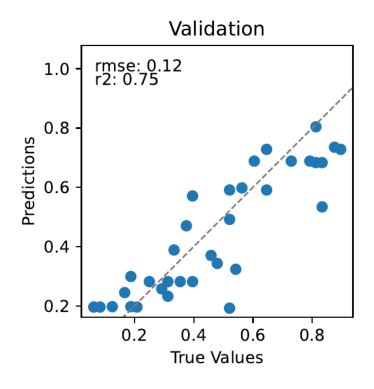

In [14]:
# predictions
fn = f"{f_name}_predictions_val.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



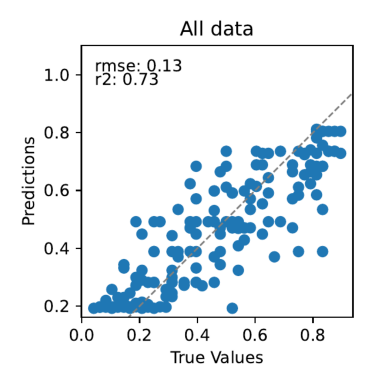

In [15]:
# predictions
fn = f"{f_name}_predictions_all.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



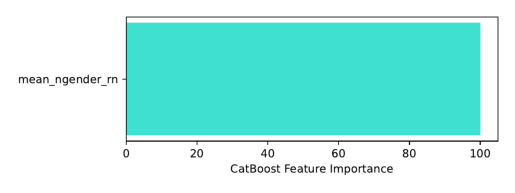

In [16]:
# predictions
fn = f"{f_name}_feature_importance.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



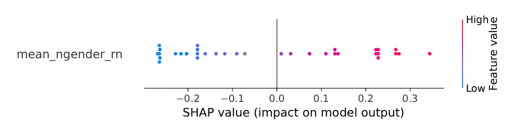

In [17]:
# predictions
fn = f"{f_name}_shap.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()

